# Medication dose: what the records support, OFF-washout adjustment, and the non-levodopa patient

The review asked whether the tremor-dominant result persists after accounting for levodopa-equivalent
daily dose (LEDD). `2.28` covered session order, site, the colour-orientation mapping and disease
severity, and left LEDD out. This notebook does what the records allow.

1. **What can be derived.** The only medication field is free-text prescriptions (`pd_meds`). A daily
   dose needs strength *and* frequency; frequency is written down for only some patients. Each regimen
   is transcribed by hand below, so a clinician can check it line by line, and LEDD is computed only
   where the record supports it, with the conversion factors of Tomlinson et al. (2010).
2. **OFF-washout duration**, which *is* recorded for all 21 patients, as a dose-related covariate: how
   long the patient had been off medication at the OFF session bounds how complete the OFF state was.
3. **The patient not on levodopa.** P22 (bradykinesia-dominant) takes rasagiline and a rotigotine
   patch, no levodopa, so their ON/OFF manipulation is pharmacologically different. Both the subtype
   model and the joint three-way model are refitted without P22.

Model fits reuse the reported model, priors and sampler settings (`2.28`, `2.27`). Outputs go to the
gitignored `outputs/` directory; nothing is written to the data directory.

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *

In [2]:
import pymc as pm

from config import dir_config
from src.utils import classification_utils
from src.utils.mcmc_cache import FIT_SETTINGS, TERMS, prepare_trials, rhat

processed_dir = Path(dir_config.data.processed)
filtered_data = pd.read_csv(Path(processed_dir, "processed_all_data_accu_60_filtered.csv"), index_col=None)
processed_metadata = pd.read_csv(Path(processed_dir, "processed_metadata_all_data_accu_60.csv"), index_col=None)
subjects_map, _ = classification_utils.get_subject_classification_ids(processed_metadata)

OUTPUT_DIR = (Path.cwd().parent / "outputs").resolve()
assert not str(OUTPUT_DIR).startswith(str(processed_dir.parents[0])), "never write to the data dir"
OUTPUT_DIR.mkdir(exist_ok=True)

SUBTYPES = {"tremor": "tremor_dominant", "bradykinetic": "bradykinesia_dominant"}
TITLES = {"tremor": "Tremor Dominant", "bradykinetic": "Bradykinesia Dominant"}
subtype_of = {p: s for s, key in SUBTYPES.items() for p in subjects_map[key]}
print({s: len(subjects_map[k]) for s, k in SUBTYPES.items()})

PD subjects with ON+OFF sessions: 41
PD subjects with UPDRS subtype: 22
All PD subjects:           41
  Tremor dominant:         11 	 ['P3' 'P6' 'P7' 'P11' 'P12' 'P17' 'P18' 'P19' 'P29' 'P31' 'P32']
  Brady dominant:          10 	 ['P1' 'P4' 'P9' 'P13' 'P20' 'P22' 'P23' 'P28' 'P33' 'P34']
  Intermediate:            1 	 ['P24']
HC subjects:               18 	 ['HC1' 'HC3' 'HC6' 'HC7' 'HC8' 'HC9' 'HC12' 'HC13' 'AV' 'BC' 'BF' 'EM'
 'ES' 'GF' 'GP' 'JA' 'MRM' 'SY']
{'tremor': 11, 'bradykinetic': 10}


## Part 1. What the prescription records support

Every patient's `pd_meds` entry, transcribed. `frequency recorded` means the entry states how many
tablets are taken per day; without it a tablet strength (e.g. "25-100 mg tablet") says nothing about the
daily dose. Conversion factors (Tomlinson et al., 2010, *Mov Disord* 25:2649): immediate-release
levodopa x 1, controlled-release levodopa x 0.75, amantadine x 1, rasagiline x 100, rotigotine x 30.
Gabapentin and trihexyphenidyl carry no LEDD.

P33's entry gives the prescription (1 tablet three times a day) and a note that the patient reports
taking it four times a day. LEDD uses the reported intake (400 mg); the prescribed 300 mg is listed too.

In [3]:
# levodopa in mg/day (immediate- and controlled-release), other dopaminergic LEDD, as written in pd_meds.
# None = not derivable from the record (strength without frequency).
REGIMENS = {
    #       formulation      IR mg/day  CR mg/day  other LEDD  basis
    "P1":  ("levodopa IR",   None,      None,      0,          "25-100 tablet, no frequency; gabapentin (no LEDD)"),
    "P3":  ("levodopa IR",   None,      None,      0,          "25-100 tablet, no frequency"),
    "P4":  ("levodopa CR",   None,      None,      0,          "CR 25-100 tablet, no frequency"),
    "P6":  ("levodopa IR",   None,      None,      0,          "25-100 tablet, no frequency"),
    "P7":  ("levodopa CR",   None,      None,      0,          "CR 25-100 tablet, no frequency"),
    "P9":  ("levodopa IR",   None,      None,      0,          "25-100 tablet, no frequency"),
    "P11": ("levodopa IR",   None,      None,      0,          "25-100 tablet, no frequency"),
    "P12": ("levodopa IR",   None,      None,      0,          "25-100 tablet, no frequency"),
    "P13": ("levodopa CR",   None,      None,      0,          "CR 25-100 tablet, no frequency"),
    "P17": ("levodopa IR",   None,      None,      0,          "25-100 tablet, no frequency"),
    "P18": ("levodopa IR",   None,      None,      0,          "25-100 tablet, no frequency"),
    "P19": ("levodopa IR",   None,      None,      0,          "25-100 tablet, no frequency"),
    "P20": ("levodopa CR",   None,      None,      0,          "CR 25-100 tablet, no frequency"),
    "P22": ("no levodopa",   0,         0,         100 + 90,   "rasagiline 1 mg/day (x100) + rotigotine 3 mg/24 h patch (x30)"),
    "P23": ("levodopa IR",   None,      None,      0,          "25-100 tablet, no frequency"),
    "P28": ("levodopa IR",   300,       0,         0,          "1 tab x 3/day"),
    "P29": ("levodopa IR+CR", 400,      200,       0,          "IR 2 tabs x 2/day; CR 2 tabs nightly"),
    "P31": ("levodopa IR",   450,       0,         0,          "1.5 tabs x 3/day"),
    "P32": ("levodopa IR",   450,       0,         0,          "1.5 tabs x 3/day"),
    "P33": ("levodopa IR",   400,       0,         0,          "prescribed 1 tab x 3/day (300); reports 4/day (400) - reported used"),
    "P34": ("levodopa IR",   800,       0,         200,        "2 tabs x 4/day; amantadine 100 mg x 2/day"),
}

first = processed_metadata.drop_duplicates("subject_id").set_index("subject_id")
off_sessions = processed_metadata[processed_metadata["treatment"] == "OFF"].set_index("subject_id")

rows = []
for pid, (form, ir, cr, other, basis) in REGIMENS.items():
    derivable = ir is not None
    rows.append({"participant": pid, "subtype": subtype_of[pid], "formulation": form,
                 "frequency recorded": derivable,
                 "LEDD (mg/day)": ir + 0.75 * cr + other if derivable else np.nan,
                 "OFF washout (h)": off_sessions.loc[pid, "off_meds_hrs"], "basis": basis,
                 "pd_meds (record)": " ".join(str(first.loc[pid, "pd_meds"]).split())})
dose = pd.DataFrame(rows).set_index("participant").sort_values(["subtype", "LEDD (mg/day)"])
assert set(dose.index) == set(subtype_of), "every subtyped patient has a transcribed regimen"
dose.drop(columns="pd_meds (record)")

,subtype,formulation,frequency recorded,LEDD (mg/day),OFF washout (h),basis
participant,,,,,,
P22,bradykinetic,no levodopa,True,190.0,24.00,rasagiline 1 mg/day (x100) + rotigotine 3 mg/2...
P28,bradykinetic,levodopa IR,True,300.0,17.70,1 tab x 3/day
P33,bradykinetic,levodopa IR,True,400.0,15.33,prescribed 1 tab x 3/day (300); reports 4/day ...
P34,bradykinetic,levodopa IR,True,1000.0,15.50,2 tabs x 4/day; amantadine 100 mg x 2/day
P1,bradykinetic,levodopa IR,False,NaN,24.00,"25-100 tablet, no frequency; gabapentin (no LEDD)"
P4,bradykinetic,levodopa CR,False,NaN,25.00,"CR 25-100 tablet, no frequency"
P9,bradykinetic,levodopa IR,False,NaN,16.00,"25-100 tablet, no frequency"
P13,bradykinetic,levodopa CR,False,NaN,25.00,"CR 25-100 tablet, no frequency"
P20,bradykinetic,levodopa CR,False,NaN,23.50,"CR 25-100 tablet, no frequency"


In [4]:
coverage = dose.groupby("subtype").agg(
    patients=("formulation", "size"),
    LEDD_derivable=("frequency recorded", "sum"),
    on_levodopa=("formulation", lambda f: int((f != "no levodopa").sum())),
    controlled_release=("formulation", lambda f: int(f.str.contains("CR").sum())),
    washout_median_h=("OFF washout (h)", "median"),
    washout_min_h=("OFF washout (h)", "min"),
    washout_max_h=("OFF washout (h)", "max"))
washout_test = stats.mannwhitneyu(dose.loc[dose["subtype"] == "tremor", "OFF washout (h)"],
                                  dose.loc[dose["subtype"] == "bradykinetic", "OFF washout (h)"])
print(f"LEDD derivable for {int(dose['frequency recorded'].sum())} of {len(dose)} patients")
print(f"OFF washout, tremor vs bradykinesia: Mann-Whitney U = {washout_test.statistic:.1f}, p = {washout_test.pvalue:.3f}")
coverage

LEDD derivable for 7 of 21 patients
OFF washout, tremor vs bradykinesia: Mann-Whitney U = 22.5, p = 0.024


,patients,LEDD_derivable,on_levodopa,controlled_release,washout_median_h,washout_min_h,washout_max_h
subtype,,,,,,,
bradykinetic,10,4,9,3,22.0,15.33,25.00
tremor,11,3,11,2,15.0,12.00,38.25


**LEDD cannot be used as a covariate.** It is derivable for 7 of 21 patients (3 tremor-dominant, 4
bradykinesia-dominant); for the other 14 the record gives tablet strength only. Imputing a "typical"
regimen for them would put a constant into the model and test nothing. Obtaining daily doses from the
clinical charts is the only route to the analysis the reviewer asked for. What the data *do* support is
below: the washout covariate (complete) and the P22 sensitivity analysis. Part 4 shows the 7 derivable
doses against each patient's medication effect, descriptively.

## Part 2. OFF-washout duration as a covariate

Washout is a between-participant covariate, so it enters exactly as session order, site and severity
did in `2.28`: centred and scaled, with its interactions on colour, medication and colour x medication.
The question is whether the colour x medication estimate moves when washout is allowed to modulate it.
The design and model code are copied unchanged from `2.28`.

In [5]:
def build(subset, covariates, extra):
    """Base design (7 columns, random effects) plus fixed covariate interactions (from 2.28)."""
    base = np.column_stack([np.ones(len(subset)), subset["coh"], subset["col"], subset["med"],
                            subset["col"] * subset["med"], subset["prev_rc"],
                            subset["prev_rc"] * subset["med"]])
    names, cols = list(TERMS), [base]
    for name in extra:
        c = covariates[name]
        block = [c, c * subset["col"], c * subset["med"], c * subset["col"] * subset["med"]]
        cols.append(np.column_stack(block)); names += [name, f"{name}:col", f"{name}:med", f"{name}:col:med"]
    return np.column_stack(cols).astype("float64"), names


def fit_adjusted(subset, design, seed=0):
    """The reported model with extra fixed effects (from 2.28)."""
    participants = subset["subject_id"].unique()
    index = subset["subject_id"].map({s: i for i, s in enumerate(participants)}).to_numpy()
    n_re = len(TERMS)
    y = subset["choice"].to_numpy().astype("int8")
    with pm.Model():
        population = pm.Normal("beta", 0, 2.5, shape=design.shape[1])
        subject_sd = pm.HalfNormal("sd_u", 1.0, shape=n_re)
        subject_z = pm.Normal("z_u", 0, 1, shape=(len(participants), n_re))
        eta = pm.math.sum(design * population, axis=1) + pm.math.sum(
            design[:, :n_re] * (subject_z * subject_sd)[index], axis=1)
        pm.Bernoulli("obs", logit_p=eta, observed=y)
        return pm.sample(FIT_SETTINGS["draws"], tune=FIT_SETTINGS["tune"], chains=FIT_SETTINGS["chains"],
                         cores=FIT_SETTINGS["chains"], target_accept=FIT_SETTINGS["target_accept"],
                         random_seed=seed, progressbar=False)


def summarise(fitted, names, term="col:med"):
    beta = fitted.posterior["beta"].values
    draws = beta[..., names.index(term)].ravel()
    low, high = np.percentile(draws, [2.5, 97.5])
    return {"estimate": draws.mean(), "2.5%": low, "97.5%": high, "P(> 0)": (draws > 0).mean(),
            "divergences": int(fitted.sample_stats["diverging"].values.sum()),
            "max r_hat": max(rhat(beta[..., k]) for k in range(beta.shape[-1]))}


reported = pd.read_csv(OUTPUT_DIR / "covariate_adjustment.csv").set_index(["subtype", "model"])
subsets = {s: prepare_trials(filtered_data, subjects_map[key]) for s, key in SUBTYPES.items()}

washout_rows = []
for subtype, subset in subsets.items():
    hours = dose.loc[subset["subject_id"], "OFF washout (h)"].to_numpy(dtype=float)
    covariates = {"washout": (hours - np.mean(hours)) / np.std(hours)}
    r = reported.loc[(subtype, "reported model")]
    washout_rows.append({"subtype": subtype, "model": "reported model (2.28)", "estimate": r["col:med"],
                         "2.5%": r["2.5%"], "97.5%": r["97.5%"], "P(> 0)": r["P(> 0)"],
                         "divergences": r["divergences"], "max r_hat": r["max r_hat"]})
    design, names = build(subset, covariates, ["washout"])
    fitted = fit_adjusted(subset, design)
    row = {"subtype": subtype, "model": "+ OFF washout", **summarise(fitted, names)}
    row["washout:col:med"] = summarise(fitted, names, "washout:col:med")["estimate"]
    washout_rows.append(row)
    print(f"{subtype:13s} + OFF washout   col:med = {row['estimate']:+.3f} [{row['2.5%']:+.3f}, {row['97.5%']:+.3f}] "
          f"P(>0) = {row['P(> 0)']:.3f}   divergences = {row['divergences']}")

washout_adjusted = pd.DataFrame(washout_rows).set_index(["subtype", "model"])
washout_adjusted.round(3)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, sd_u, z_u]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 178 seconds.
Initializing NUTS using jitter+adapt_diag...


tremor        + OFF washout   col:med = +0.531 [-0.073, +1.106] P(>0) = 0.963   divergences = 0


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, sd_u, z_u]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 113 seconds.


bradykinetic  + OFF washout   col:med = +0.057 [-0.513, +0.638] P(>0) = 0.583   divergences = 0


estimate   2.5%  97.5%  P(> 0)  \
subtype      model                                                   
tremor       reported model (2.28)     0.544 -0.009  1.082   0.974   
             + OFF washout             0.531 -0.073  1.106   0.963   
bradykinetic reported model (2.28)     0.053 -0.512  0.606   0.577   
             + OFF washout             0.057 -0.513  0.638   0.583   

                                    divergences  max r_hat  washout:col:med  
subtype      model                                                           
tremor       reported model (2.28)          0.0      1.005              NaN  
             + OFF washout                  0.0      1.005            0.235  
bradykinetic reported model (2.28)          0.0      1.004              NaN  
             + OFF washout                  0.0      1.002           -0.216

## Part 3. Excluding P22, the patient not on levodopa

P22 is bradykinesia-dominant, so the tremor-dominant fit is unaffected. Two refits: the
bradykinesia-dominant model, and the joint model whose three-way coefficient is the direct subtype
comparison (`2.27`, same specification and sampler settings).

In [6]:
brady_without = subsets["bradykinetic"][subsets["bradykinetic"]["subject_id"] != "P22"].reset_index(drop=True)
design, names = build(brady_without, {}, [])
brady_fit = fit_adjusted(brady_without, design)
brady_row = summarise(brady_fit, names)
print(f"bradykinesia-dominant without P22 ({brady_without['subject_id'].nunique()} patients): "
      f"col:med = {brady_row['estimate']:+.3f} [{brady_row['2.5%']:+.3f}, {brady_row['97.5%']:+.3f}] P(>0) = {brady_row['P(> 0)']:.3f}")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, sd_u, z_u]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 74 seconds.


bradykinesia-dominant without P22 (9 patients): col:med = +0.180 [-0.372, +0.738] P(>0) = 0.762


In [7]:
SUBTYPE_CODE = {"tremor": 0.5, "bradykinetic": -0.5}
JOINT_TERMS = TERMS + [f"sub:{t}" if t != "intercept" else "sub" for t in TERMS]


def fit_joint(frames, seed=FIT_SETTINGS["seed"]):
    """The 2.27 joint model: subtype interacts with every within-participant term."""
    joint = pd.concat(frames, ignore_index=True)
    participants = joint["subject_id"].unique()
    index = joint["subject_id"].map({s: i for i, s in enumerate(participants)}).to_numpy()
    within = np.column_stack([np.ones(len(joint)), joint["coh"], joint["col"], joint["med"],
                              joint["col"] * joint["med"], joint["prev_rc"], joint["prev_rc"] * joint["med"]])
    design = np.column_stack([within, within * joint["sub"].to_numpy()[:, None]]).astype("float64")
    outcomes = joint["choice"].to_numpy().astype("int8")
    n_within = len(TERMS)
    with pm.Model():
        population = pm.Normal("beta", 0, 2.5, shape=design.shape[1])
        subject_sd = pm.HalfNormal("sd_u", 1.0, shape=n_within)
        subject_z = pm.Normal("z_u", 0, 1, shape=(len(participants), n_within))
        eta = pm.math.sum(design * population, axis=1) + pm.math.sum(
            design[:, :n_within] * (subject_z * subject_sd)[index], axis=1)
        pm.Bernoulli("obs", logit_p=eta, observed=outcomes)
        return pm.sample(FIT_SETTINGS["draws"], tune=FIT_SETTINGS["tune"], chains=FIT_SETTINGS["chains"],
                         cores=FIT_SETTINGS["chains"], target_accept=FIT_SETTINGS["target_accept"],
                         random_seed=seed, progressbar=False)


frames = [subsets["tremor"].assign(sub=SUBTYPE_CODE["tremor"]), brady_without.assign(sub=SUBTYPE_CODE["bradykinetic"])]
joint_fit = fit_joint(frames)
joint_row = summarise(joint_fit, JOINT_TERMS, "sub:col:med")
print(f"three-way (TD-PD minus BD-PD) without P22: {joint_row['estimate']:+.3f} "
      f"[{joint_row['2.5%']:+.3f}, {joint_row['97.5%']:+.3f}] P(>0) = {joint_row['P(> 0)']:.3f}   "
      f"divergences = {joint_row['divergences']}   max r_hat = {joint_row['max r_hat']:.4f}")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, sd_u, z_u]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 261 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


three-way (TD-PD minus BD-PD) without P22: +0.354 [-0.375, +1.093] P(>0) = 0.840   divergences = 0   max r_hat = 1.0104


In [8]:
reported_three_way = pd.read_csv(OUTPUT_DIR / "subtype_comparison.csv", index_col=0).iloc[0]
r = reported.loc[("bradykinetic", "reported model")]
p22 = pd.DataFrame([
    {"estimate": "bradykinesia col:med", "fit": "all 10 (2.28)", "mean": r["col:med"], "2.5%": r["2.5%"], "97.5%": r["97.5%"], "P(> 0)": r["P(> 0)"]},
    {"estimate": "bradykinesia col:med", "fit": "without P22", "mean": brady_row["estimate"], "2.5%": brady_row["2.5%"], "97.5%": brady_row["97.5%"], "P(> 0)": brady_row["P(> 0)"]},
    {"estimate": "three-way (TD minus BD)", "fit": "all 21 (2.27)", "mean": reported_three_way["mean"], "2.5%": reported_three_way["2.5%"], "97.5%": reported_three_way["97.5%"], "P(> 0)": reported_three_way["P(> 0)"]},
    {"estimate": "three-way (TD minus BD)", "fit": "without P22", "mean": joint_row["estimate"], "2.5%": joint_row["2.5%"], "97.5%": joint_row["97.5%"], "P(> 0)": joint_row["P(> 0)"]},
]).set_index(["estimate", "fit"])
p22.round(3)

mean   2.5%  97.5%  P(> 0)
estimate                fit                                       
bradykinesia col:med    all 10 (2.28)  0.053 -0.512  0.606   0.577
                        without P22    0.180 -0.372  0.738   0.762
three-way (TD minus BD) all 21 (2.27)  0.469 -0.291  1.241   0.897
                        without P22    0.354 -0.375  1.093   0.840

## Part 4. The seven derivable doses, descriptively

Each patient's model-based OFF to ON change in prior effect (`2.28`, posterior mean and 95% interval)
against LEDD, for the 7 patients whose record supports a daily dose. Seven points across two subtypes
cannot support a test; this is shown so the reader can see there is no obvious dose ordering, not as
evidence that dose does not matter.

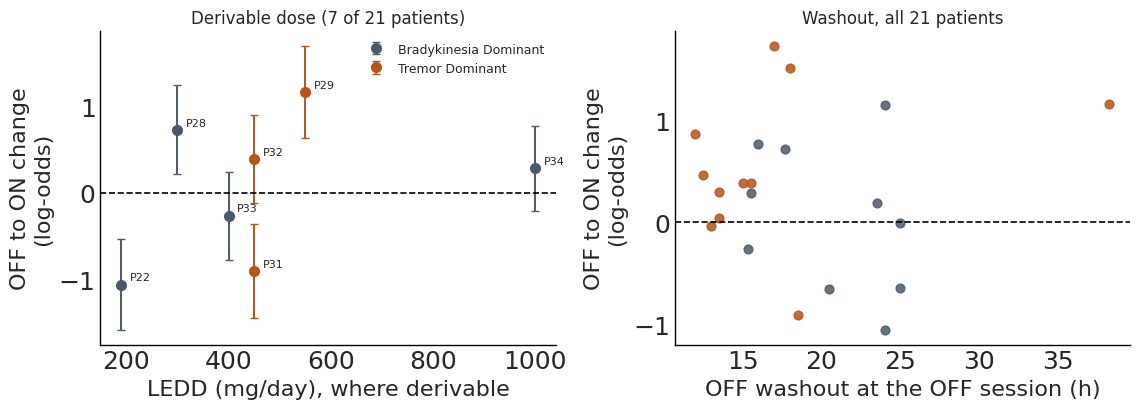

bradykinetic: Spearman rho(washout, change) = -0.26, p = 0.48
tremor: Spearman rho(washout, change) = +0.21, p = 0.55


In [9]:
paired = pd.read_csv(OUTPUT_DIR / "paired_participant_changes.csv", index_col=0)
known = dose[dose["frequency recorded"]].join(paired[["change", "change_lo", "change_hi"]])
colors = {"tremor": "#B5541D", "bradykinetic": "#4A5A6B"}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax = axes[0]
for subtype, block in known.groupby("subtype"):
    ax.errorbar(block["LEDD (mg/day)"], block["change"], yerr=[block["change"] - block["change_lo"], block["change_hi"] - block["change"]],
                ls="", marker="o", ms=7, capsize=3, lw=1.4, color=colors[subtype], label=TITLES[subtype])
    for pid, r in block.iterrows():
        ax.annotate(pid, (r["LEDD (mg/day)"], r["change"]), xytext=(6, 3), textcoords="offset points", fontsize=8)
ax.axhline(0, color="k", ls="--", lw=1.2)
ax.set_xlabel("LEDD (mg/day), where derivable"); ax.set_ylabel("OFF to ON change\n(log-odds)")
ax.set_title(f"Derivable dose ({len(known)} of {len(dose)} patients)", fontsize=12); ax.legend(frameon=False, fontsize=9)

ax = axes[1]
both = dose.join(paired[["change"]])
for subtype, block in both.groupby("subtype"):
    ax.scatter(block["OFF washout (h)"], block["change"], s=40, color=colors[subtype], label=TITLES[subtype], alpha=0.85)
ax.axhline(0, color="k", ls="--", lw=1.2)
ax.set_xlabel("OFF washout at the OFF session (h)"); ax.set_ylabel("OFF to ON change\n(log-odds)")
ax.set_title("Washout, all 21 patients", fontsize=12)
for a in axes:
    for sp in ["top", "right"]: a.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "medication_dose.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "medication_dose.png", dpi=200, bbox_inches="tight"); plt.show()
rho = {s: stats.spearmanr(b["OFF washout (h)"], b["change"]) for s, b in both.groupby("subtype")}
for s, r in rho.items():
    print(f"{s}: Spearman rho(washout, change) = {r.statistic:+.2f}, p = {r.pvalue:.2f}")

In [10]:
dose.to_csv(OUTPUT_DIR / "medication_dose_table.csv")
coverage.to_csv(OUTPUT_DIR / "medication_dose_coverage.csv")
washout_adjusted.to_csv(OUTPUT_DIR / "washout_adjustment.csv")
p22.to_csv(OUTPUT_DIR / "p22_exclusion.csv")
print("saved medication_dose_table, medication_dose_coverage, washout_adjustment, p22_exclusion, medication_dose figure")

saved medication_dose_table, medication_dose_coverage, washout_adjustment, p22_exclusion, medication_dose figure
